# urbanev eda

shenzhen bolge duzeyi saatlik veri 1 eylul 2022 - 28 subat 2023
bu notebookta dosya yapisina eksik veriye bolge dagilimina ve zaman icindeki doluluga bakiyorum
model egitmiyorum

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

from src.urbanev import load_zone_tables, occupancy_ratio

urbanev_dir = project_dir / "data" / "raw" / "UrbanEVDataset"
figures = project_dir / "reports" / "figures"
figures.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
blue, orange = "#2a78d6", "#eb6834"


## 1 dosyalar

occupancy.csv nin birimini degerlerden kontrol ediyorum
dryad degisiklik kaydi bu dosyanin orandan dolu nokta sayisina gectigini yaziyor

In [2]:
tables = load_zone_tables(urbanev_dir)
occupancy, zones = tables["occupancy"], tables["zones"]
print("occupancy boyut:", occupancy.shape)
print("tarih:", occupancy.index.min(), occupancy.index.max())
print("eksik hucre:", int(occupancy.isna().sum().sum()))
print("min max:", occupancy.min().min(), occupancy.max().max())
print("tam sayi degil hucre:", int((occupancy.stack() % 1 != 0).sum()))
print("kapasite toplami:", int(zones["charge_count"].sum()))
print("saatlik adim tek mi:", occupancy.index.to_series().diff().dropna().nunique() == 1)
occupancy.iloc[:3, :4]

occupancy boyut: (4344, 275)
tarih: 2022-09-01 00:00:00 2023-02-28 23:00:00
eksik hucre: 0
min max: 0.0 373.0
tam sayi degil hucre: 691
kapasite toplami: 23441
saatlik adim tek mi: True


,102,104,105,106
time,,,,
2022-09-01 00:00:00,17.0,1.0,15.0,54.0
2022-09-01 01:00:00,16.0,1.0,19.0,50.0
2022-09-01 02:00:00,16.0,1.0,20.0,44.0


## 2 ham istasyon verisinde eksik

temiz saatlik tabloda eksik yok ama ham 5 dakikalik dosyalarda var
her istasyon icin busy alaninin bos oranina ve gunluk bos oranina bakiyorum

In [3]:
raw_files = sorted((urbanev_dir / "20220901-20230228_station-raw" / "charge_5min").glob("*.csv"))
station_missing = []
rows_missing = None
times = None
for path in raw_files:
    frame = pd.read_csv(path, usecols=["time", "busy"], parse_dates=["time"])
    empty = frame["busy"].isna().to_numpy()
    station_missing.append(empty.mean() * 100)
    if rows_missing is None:
        rows_missing = np.zeros(len(frame))
        times = frame["time"]
    if len(frame) != len(rows_missing):
        raise ValueError(f"satir sayisi farkli: {path.name}")
    rows_missing += empty
station_missing = pd.Series(station_missing)
daily_missing = pd.Series(rows_missing / len(raw_files) * 100, index=times).resample("D").mean()
print("dosya:", len(raw_files), "dosya basi satir:", len(rows_missing))
print("toplam eksik oran %:", round(station_missing.mean(), 2))
print("istasyon medyan %:", round(station_missing.median(), 2), "en yuksek %:", round(station_missing.max(), 2))
print("tamamen bos istasyon:", int((station_missing == 100).sum()))
print("gunluk eksik % en dusuk en yuksek:", round(daily_missing.min(), 2), round(daily_missing.max(), 2))

dosya: 1682 dosya basi satir: 52128
toplam eksik oran %: 21.16
istasyon medyan %: 10.48 en yuksek %: 100.0
tamamen bos istasyon: 21
gunluk eksik % en dusuk en yuksek: 8.75 73.37


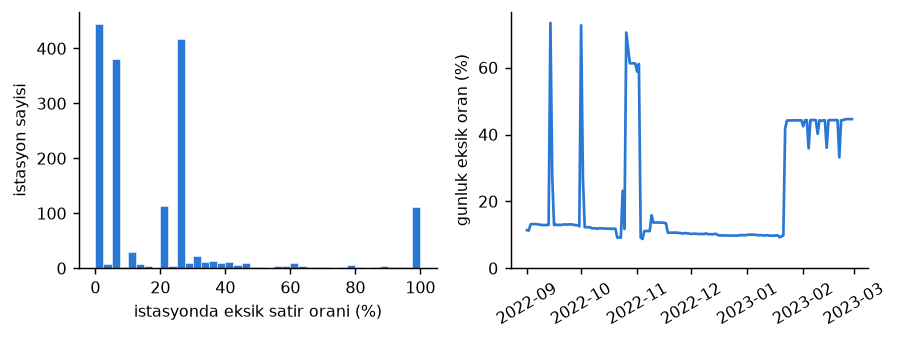

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.7))
axes[0].hist(station_missing, bins=40, color=blue, edgecolor="white", linewidth=0.3)
axes[0].set_xlabel("istasyonda eksik satir orani (%)")
axes[0].set_ylabel("istasyon sayisi")
axes[1].plot(daily_missing.index, daily_missing.to_numpy(), color=blue, linewidth=1.5)
axes[1].set_ylabel("gunluk eksik oran (%)")
axes[1].set_ylim(0)
axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(figures / "urbanev_eksik_veri.png", dpi=200, bbox_inches="tight")
plt.show()

## 3 bolge dagilimi

dolu nokta sayisini kapasiteye bolup orana ceviriyorum
bolgelerin kapasitesi cok farkli oldugu icin sehir genelini kapasiteye gore agirlikli aliyorum

oran en yuksek: 1.0 1 uzeri hucre: 0
sehir geneli ortalama %: 20.96
bolge ortalamasi min medyan max %: 1.73 20.32 82.09
kapasite min medyan max: 4 58.0 446
bolge-saat oran ceyrekleri: {0.5: 0.193, 0.95: 0.55, 0.99: 0.833}
tam dolu bolge-saat %: 0.621


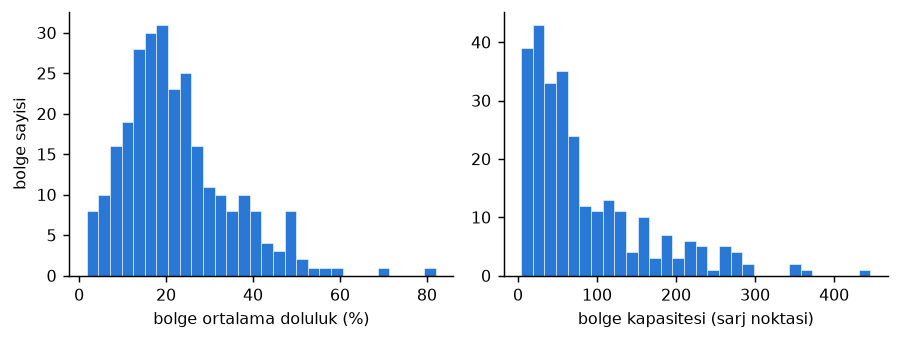

In [5]:
ratio = occupancy_ratio(occupancy, zones)
capacity = zones["charge_count"].reindex(occupancy.columns)
city = occupancy.sum(axis=1) / capacity.sum() * 100
zone_mean = ratio.mean() * 100
print("oran en yuksek:", ratio.max().max(), "1 uzeri hucre:", int(ratio.gt(1).sum().sum()))
print("sehir geneli ortalama %:", round(city.mean(), 2))
print("bolge ortalamasi min medyan max %:", round(zone_mean.min(), 2), round(zone_mean.median(), 2), round(zone_mean.max(), 2))
print("kapasite min medyan max:", capacity.min(), capacity.median(), capacity.max())
print("bolge-saat oran ceyrekleri:", ratio.stack().quantile([.5, .95, .99]).round(3).to_dict())
print("tam dolu bolge-saat %:", round(float(ratio.ge(1).sum().sum() / ratio.size * 100), 3))

fig, axes = plt.subplots(1, 2, figsize=(7, 2.7))
axes[0].hist(zone_mean, bins=30, color=blue, edgecolor="white", linewidth=0.3)
axes[0].set_xlabel("bolge ortalama doluluk (%)")
axes[0].set_ylabel("bolge sayisi")
axes[1].hist(capacity, bins=30, color=blue, edgecolor="white", linewidth=0.3)
axes[1].set_xlabel("bolge kapasitesi (sarj noktasi)")
fig.tight_layout()
fig.savefig(figures / "urbanev_bolge_dagilimi.png", dpi=200, bbox_inches="tight")
plt.show()

## 4 zaman icinde doluluk

en dusuk 5 gun: {Timestamp('2022-11-02 00:00:00'): 11.7, Timestamp('2022-11-01 00:00:00'): 11.8, Timestamp('2023-02-02 00:00:00'): 15.4, Timestamp('2023-02-01 00:00:00'): 15.4, Timestamp('2023-01-21 00:00:00'): 15.9}


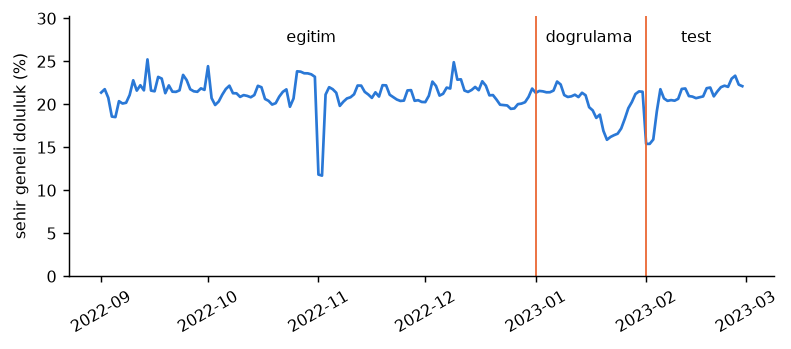

In [6]:
daily = city.resample("D").mean()
print("en dusuk 5 gun:", daily.nsmallest(5).round(1).to_dict())
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.plot(daily.index, daily.to_numpy(), color=blue, linewidth=1.5)
ax.axvline(pd.Timestamp("2023-01-01"), color=orange, linewidth=1)
ax.axvline(pd.Timestamp("2023-02-01"), color=orange, linewidth=1)
ax.text(pd.Timestamp("2022-10-30"), daily.max() * 1.08, "egitim", ha="center")
ax.text(pd.Timestamp("2023-01-16"), daily.max() * 1.08, "dogrulama", ha="center")
ax.text(pd.Timestamp("2023-02-15"), daily.max() * 1.08, "test", ha="center")
ax.set_ylim(0, daily.max() * 1.2)
ax.set_ylabel("sehir geneli doluluk (%)")
ax.tick_params(axis="x", rotation=30)
fig.savefig(figures / "urbanev_zaman_doluluk.png", dpi=200, bbox_inches="tight")
plt.show()

## 5 saatlik profil ve fiyat

iki farkli birim oldugu icin alt alta ciziyorum

en yuksek saat: 1 24.92 en dusuk saat: 15 17.44
hafta ici hafta sonu %: 20.67 21.68
saatlik profil korelasyonu: -0.955


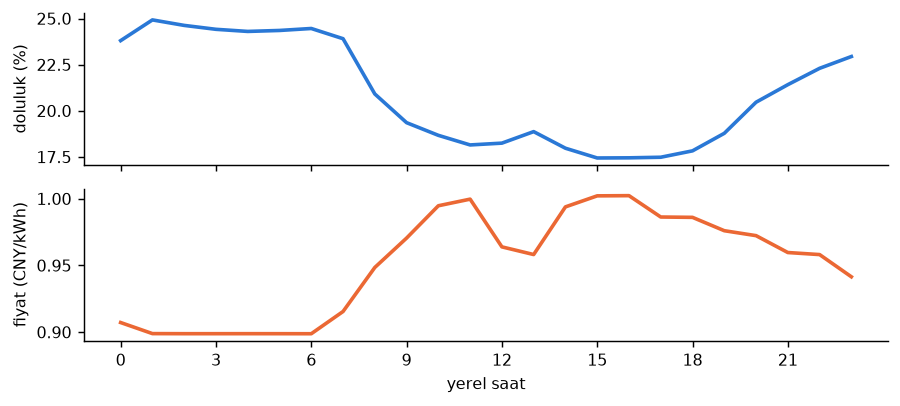

In [7]:
by_hour = city.groupby(city.index.hour).mean()
price = tables["e_price"].mean(axis=1)
price_hour = price.groupby(price.index.hour).mean()
weekday = city[city.index.dayofweek < 5].mean()
weekend = city[city.index.dayofweek >= 5].mean()
print("en yuksek saat:", int(by_hour.idxmax()), round(by_hour.max(), 2), "en dusuk saat:", int(by_hour.idxmin()), round(by_hour.min(), 2))
print("hafta ici hafta sonu %:", round(weekday, 2), round(weekend, 2))
print("saatlik profil korelasyonu:", round(float(np.corrcoef(by_hour, price_hour)[0, 1]), 3))

fig, axes = plt.subplots(2, 1, figsize=(7, 3.2), sharex=True)
axes[0].plot(by_hour.index, by_hour.to_numpy(), color=blue, linewidth=2)
axes[0].set_ylabel("doluluk (%)")
axes[1].plot(price_hour.index, price_hour.to_numpy(), color=orange, linewidth=2)
axes[1].set_ylabel("fiyat (CNY/kWh)")
axes[1].set_xlabel("yerel saat")
axes[1].set_xticks(range(0, 24, 3))
fig.tight_layout()
fig.savefig(figures / "urbanev_saat_fiyat.png", dpi=200, bbox_inches="tight")
plt.show()

## sonuc

hazir saatlik tabloda eksik yok ham istasyon dosyalarinda var
doluluk gece yuksek ogleden sonra dusuk ucuz saatlerle ayni yonde
sonraki notebookta modele hazir tabloyu cikariyorum